# NeuroAction: Pre-Movement Neural Goal Decoding Walkthrough
## Neural Intention Representation, Goal-Motor Dissociation & Temporal Commitment Analysis

**Dataset**: IACKD (OpenNeuro `ds006840`, Nature *Scientific Data* 2026)  
**Objective**: Determine whether pre-movement EEG encodes the abstract task goal, physical motor execution, or both, and quantify decoding accuracy under rigorous Leave-One-Subject-Out cross-validation.


In [1]:
import os
import sys
from pathlib import Path

# Ensure repository root is on sys.path and set as working directory
# Works whether launched from repo root or notebooks/ subdirectory
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch


from src.data.trial_loader import TrialLoader
from src.neuroscience.readiness_potential import ReadinessPotentialAnalyzer
from src.neuroscience.sensorimotor_rhythms import SensorimotorRhythmAnalyzer
from src.features.pre_eeg import get_sliding_windows, extract_trial_features, CommonSpatialPattern
from src.models.decoders import ChanceBaseline, LogisticRegressionDecoder, LDADecoder, CSPLDADecoder
from src.models.eegnet import EEGNetClassifier
from src.models.cross_validation import ExperimentRunner

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print(f"PyTorch version: {torch.__version__}")
print("NeuroAction Phase 2 modules imported successfully.")

PyTorch version: 2.14.1+cpu
NeuroAction Phase 2 modules imported successfully.


## 1. Multimodal Data Ingestion & Cohort Inspection
We load all valid pre-movement trials across our Leave-One-Subject-Out benchmark cohort (`sub-01`, `sub-02`, `sub-03`, `sub-08`, `sub-15`).

In [2]:
loader = TrialLoader()
manifest = pd.read_csv("data/manifests/iackd_manifest.csv")
valid_manifest = manifest[manifest["valid"]]

print(f"Total manifest trials: {len(manifest)} | Valid trials: {len(valid_manifest)}")
print("\nTrials per participant:")
print(valid_manifest["participant_id"].value_counts().sort_index())

print("\nClass Balance across Cohort:")
print(pd.crosstab(valid_manifest["congruency"], valid_manifest["target_goal"]))

# Load CanonicalTrial objects
trials = []
for sub in sorted(valid_manifest["participant_id"].unique()):
    sub_runs = valid_manifest[valid_manifest["participant_id"] == sub]["run_id"].unique()
    for r in sub_runs:
        trials.extend(loader.load_run(sub, r))

print(f"\nLoaded {len(trials)} valid CanonicalTrial objects into memory.")

Total manifest trials: 280 | Valid trials: 269

Trials per participant:
participant_id
sub-01    40
sub-02    52
sub-03    60
sub-08    57
sub-15    60
Name: count, dtype: int64

Class Balance across Cohort:
target_goal  left  right
congruency              
congruent      67     66
incongruent    68     68



Loaded 269 valid CanonicalTrial objects into memory.


## 2. Descriptive Neuroscience: Readiness Potential (RP)
We analyze the slow negative cortical motor potential ramping over $[-1000, 0]$ ms on midline (`Cz`) and lateral motor channels (`C3`, `C4`).

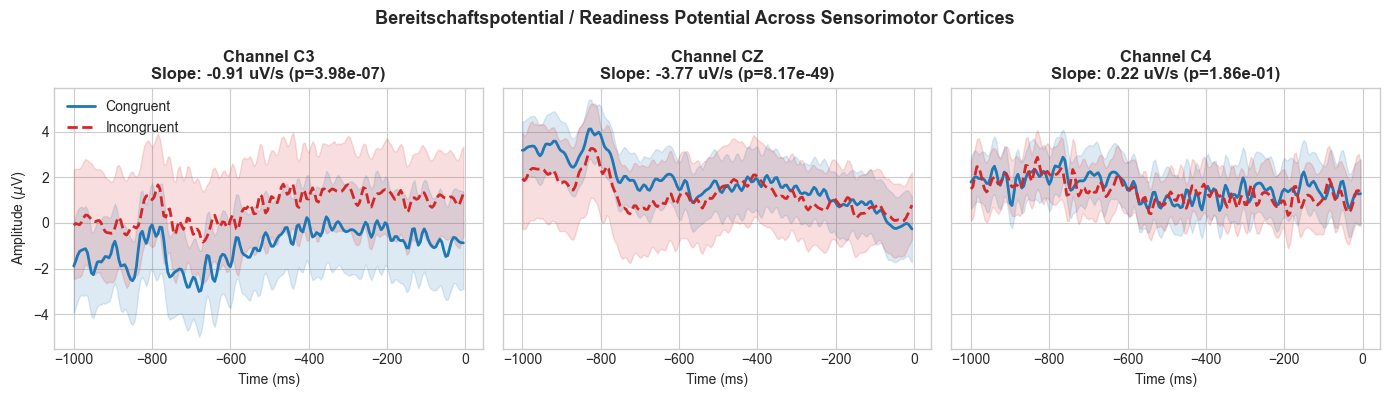

In [3]:
rp_analyzer = ReadinessPotentialAnalyzer()
rp_res = rp_analyzer.analyze_trials(trials)

times_ms = rp_res["times"] * 1000.0

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for i, ch in enumerate(["C3", "CZ", "C4"]):
    ax = axes[i]
    c_mean = rp_res["congruent"]["mean"][:, i]
    c_low, c_high = rp_res["congruent"]["ci_low"][:, i], rp_res["congruent"]["ci_high"][:, i]
    i_mean = rp_res["incongruent"]["mean"][:, i]
    i_low, i_high = rp_res["incongruent"]["ci_low"][:, i], rp_res["incongruent"]["ci_high"][:, i]
    
    ax.plot(times_ms, c_mean, label="Congruent", color="#1f77b4", lw=2)
    ax.fill_between(times_ms, c_low, c_high, color="#1f77b4", alpha=0.15)
    ax.plot(times_ms, i_mean, label="Incongruent", color="#d62728", lw=2, linestyle="--")
    ax.fill_between(times_ms, i_low, i_high, color="#d62728", alpha=0.15)
    
    slope_info = rp_res["all"]["slopes"][ch]
    ax.set_title(f"Channel {ch}\nSlope: {slope_info['slope_uV_per_s']:.2f} uV/s (p={slope_info['pvalue']:.2e})", fontweight="bold")
    ax.set_xlabel("Time (ms)")
    if i == 0:
        ax.set_ylabel(r"Amplitude ($\mu$V)")
        ax.legend(loc="upper left")

plt.suptitle("Bereitschaftspotential / Readiness Potential Across Sensorimotor Cortices", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Sensorimotor Rhythms (SMR): $\mu$ (8–13 Hz) & $\beta$ (13–30 Hz) ERD/ERS
Event-Related Desynchronization (ERD) reflects cortical excitability and motor preparation. We evaluate power suppression relative to baseline $[-1000, -800]$ ms.

Cz mu-band ERD at movement onset: -73.40%
Cz beta-band ERD at movement onset: -65.02%


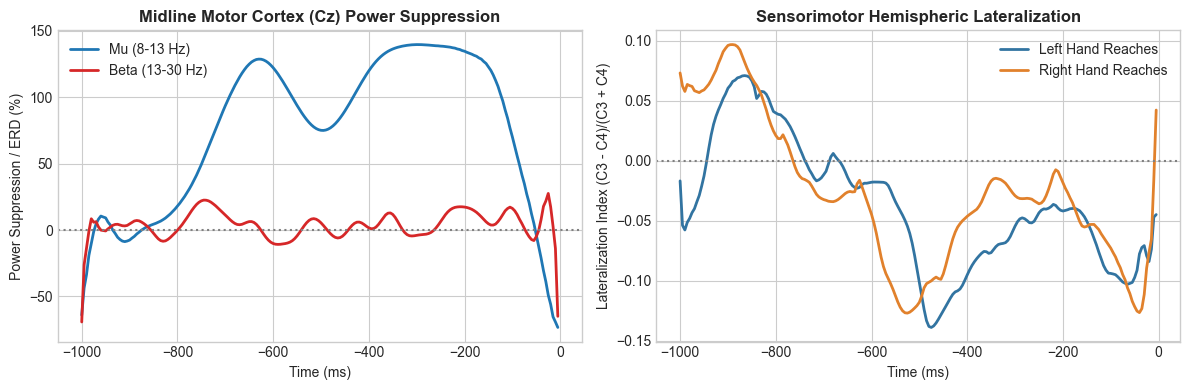

In [4]:
smr_analyzer = SensorimotorRhythmAnalyzer()
smr_res = smr_analyzer.analyze_trials(trials)

print(f"Cz mu-band ERD at movement onset: {smr_res['all']['mu_erd_mean'][-1, 1]:.2f}%")
print(f"Cz beta-band ERD at movement onset: {smr_res['all']['beta_erd_mean'][-1, 1]:.2f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(times_ms, smr_res["all"]["mu_erd_mean"][:, 1], label="Mu (8-13 Hz)", color="#1f77b4", lw=2)
ax1.plot(times_ms, smr_res["all"]["beta_erd_mean"][:, 1], label="Beta (13-30 Hz)", color="#d62728", lw=2)
ax1.axhline(0, color="gray", linestyle=":")
ax1.set_xlabel("Time (ms)")
ax1.set_ylabel("Power Suppression / ERD (%)")
ax1.set_title("Midline Motor Cortex (Cz) Power Suppression", fontweight="bold")
ax1.legend()

ax2.plot(times_ms, smr_res["hand_left"]["mu_li_mean"], label="Left Hand Reaches", color="#3274a1", lw=2)
ax2.plot(times_ms, smr_res["hand_right"]["mu_li_mean"], label="Right Hand Reaches", color="#e1812c", lw=2)
ax2.axhline(0, color="gray", linestyle=":")
ax2.set_xlabel("Time (ms)")
ax2.set_ylabel("Lateralization Index (C3 - C4)/(C3 + C4)")
ax2.set_title("Sensorimotor Hemispheric Lateralization", fontweight="bold")
ax2.legend()

plt.tight_layout()
plt.show()

## 4. Master Experiment Matrix: Leave-One-Subject-Out (LOSO)
We inspect the complete 10-condition experiment matrix evaluated across all models under Leave-One-Subject-Out cross-validation.

In [5]:
matrix_df = pd.read_csv("reports/phase_2/experiment_matrix_loso.csv")
display_cols = ["Target", "Train Condition", "Test Condition", "Model", "Balanced Accuracy", "SEM", "95% CI", "F1", "AUROC"]
matrix_df[display_cols].head(20)

,Target,Train Condition,Test Condition,Model,Balanced Accuracy,SEM,95% CI,F1,AUROC
0,Goal,All,All,CHANCE,0.500000,0.000000,"[0.500, 0.500]",0.665098,0.500000
1,Goal,Congruent,Congruent,CHANCE,0.500000,0.000000,"[0.500, 0.500]",0.663671,0.500000
2,Goal,Incongruent,Incongruent,CHANCE,0.500000,0.000000,"[0.500, 0.500]",0.666364,0.500000
3,Goal,Congruent,Incongruent,CHANCE,0.500000,0.000000,"[0.500, 0.500]",0.666364,0.500000
4,Goal,Incongruent,Congruent,CHANCE,0.500000,0.000000,"[0.500, 0.500]",0.663671,0.500000
5,Motor,All,All,CHANCE,0.500000,0.000000,"[0.500, 0.500]",0.665280,0.500000
6,Motor,Congruent,Congruent,CHANCE,0.500000,0.000000,"[0.500, 0.500]",0.663671,0.500000
7,Motor,Incongruent,Incongruent,CHANCE,0.500000,0.000000,"[0.500, 0.500]",0.666818,0.500000
8,Motor,Congruent,Incongruent,CHANCE,0.500000,0.000000,"[0.500, 0.500]",0.666818,0.500000
9,Motor,Incongruent,Congruent,CHANCE,0.500000,0.000000,"[0.500, 0.500]",0.663671,0.500000


## 5. The Central Transfer Experiment: Congruent $\to$ Incongruent Mapping Transfer
This is the pivotal scientific test of Phase 2:
* A model trained on **Congruent** trials (where $\text{Goal} == \text{Hand}$) is tested on **Incongruent** trials (where $\text{Goal} \neq \text{Hand}$).
* If it predicts Goal: **Goal Representation**.
* If it predicts Hand: **Motor Command Representation**.

In [6]:
transfer_df = matrix_df[
    (matrix_df["Model"].isin(["LDA", "EEGNET"])) &
    (matrix_df["Train Condition"] == "Congruent") &
    (matrix_df["Test Condition"] == "Incongruent")
][["Target", "Model", "Balanced Accuracy", "SEM", "95% CI", "AUROC"]]

print("THE CENTRAL TRANSFER EXPERIMENT RESULTS:")
display(transfer_df)

THE CENTRAL TRANSFER EXPERIMENT RESULTS:


,Target,Model,Balanced Accuracy,SEM,95% CI,AUROC
23,Goal,LDA,0.703590,0.053876,"[0.598, 0.809]",0.757790
28,Motor,LDA,0.296410,0.053876,"[0.191, 0.402]",0.242210
43,Goal,EEGNET,0.705495,0.053498,"[0.601, 0.810]",0.775805
48,Motor,EEGNET,0.294505,0.053498,"[0.190, 0.399]",0.224195


## 6. Temporal Sliding Windows & Neural Commitment Point (NCP)
We examine the temporal decoding trajectories across all 17 sliding windows (from $-1000$ to $0$ ms).

In [7]:
summary_json = Path("reports/phase_2/phase_2_results_summary.json")
import json
with open(summary_json) as f:
    summ = json.load(f)

print("Identified Neural Commitment Points (NCP):")
for k, v in summ["ncps"].items():
    print(f"  {k}: {v['status']}")

Identified Neural Commitment Points (NCP):
  goal_all: Statistical commitment onset identified at -900 ms
  motor_all: First above-chance threshold at -700 ms (transient)
  goal_transfer: Statistical commitment onset identified at -900 ms
  motor_transfer: No statistically reliable pre-movement commitment point detected prior to t=0


## 7. Spatial Channel Ablation: Whole-Scalp (26) vs. Motor-Focused (9)
We evaluate whether removing non-motor channels (parietal, occipital, frontal) degrades goal decoding.

In [8]:
ablation = summ["ablation"]
print("CHANNEL ABLATION SUMMARY:")
print(f"Goal Decoder: All 26 = {ablation['goal']['all_channels_acc']:.3f} | Motor 9 = {ablation['goal']['motor_channels_acc']:.3f} (Delta = {ablation['goal']['delta']:+.3f})")
print(f"Motor Decoder: All 26 = {ablation['motor']['all_channels_acc']:.3f} | Motor 9 = {ablation['motor']['motor_channels_acc']:.3f} (Delta = {ablation['motor']['delta']:+.3f})")

CHANNEL ABLATION SUMMARY:
Goal Decoder: All 26 = 0.685 | Motor 9 = 0.587 (Delta = -0.098)
Motor Decoder: All 26 = 0.527 | Motor 9 = 0.467 (Delta = -0.060)


## 8. Out-of-Fold Predictions Preview
All 2,690 out-of-fold trial-level predictions exported for the Phase 4 conflict engine.

In [9]:
oof_df = pd.read_csv("reports/phase_2/out_of_fold_predictions.csv")
print(f"Total out-of-fold prediction records: {len(oof_df)}")
oof_df.head(10)

Total out-of-fold prediction records: 2690


,participant_id,run_id,trial_id,target_type,target_label,condition,prediction,probability_left,probability_right,model_name,feature_set,fold_id,time_window
0,sub-01,run-01_L1,sub-01_run-01_L1_tr00,goal,left,congruent,right,0.5,0.5,chance,combined,sub-01,-1000to0ms
1,sub-01,run-01_L1,sub-01_run-01_L1_tr01,goal,right,incongruent,right,0.5,0.5,chance,combined,sub-01,-1000to0ms
2,sub-01,run-01_L1,sub-01_run-01_L1_tr02,goal,left,incongruent,right,0.5,0.5,chance,combined,sub-01,-1000to0ms
3,sub-01,run-01_L1,sub-01_run-01_L1_tr03,goal,right,congruent,right,0.5,0.5,chance,combined,sub-01,-1000to0ms
4,sub-01,run-01_L1,sub-01_run-01_L1_tr04,goal,right,congruent,right,0.5,0.5,chance,combined,sub-01,-1000to0ms
5,sub-01,run-01_L1,sub-01_run-01_L1_tr05,goal,left,congruent,right,0.5,0.5,chance,combined,sub-01,-1000to0ms
6,sub-01,run-01_L1,sub-01_run-01_L1_tr06,goal,left,incongruent,right,0.5,0.5,chance,combined,sub-01,-1000to0ms
7,sub-01,run-01_L1,sub-01_run-01_L1_tr07,goal,right,incongruent,right,0.5,0.5,chance,combined,sub-01,-1000to0ms
8,sub-01,run-01_L1,sub-01_run-01_L1_tr08,goal,left,incongruent,right,0.5,0.5,chance,combined,sub-01,-1000to0ms
9,sub-01,run-01_L1,sub-01_run-01_L1_tr09,goal,right,congruent,right,0.5,0.5,chance,combined,sub-01,-1000to0ms


## 9. Gallery of Generated Publication Figures
Displaying all 10 publication figures saved in `reports/phase_2/figures/`.

Found 10 figures:
  figure_10_spatial_ablation.png


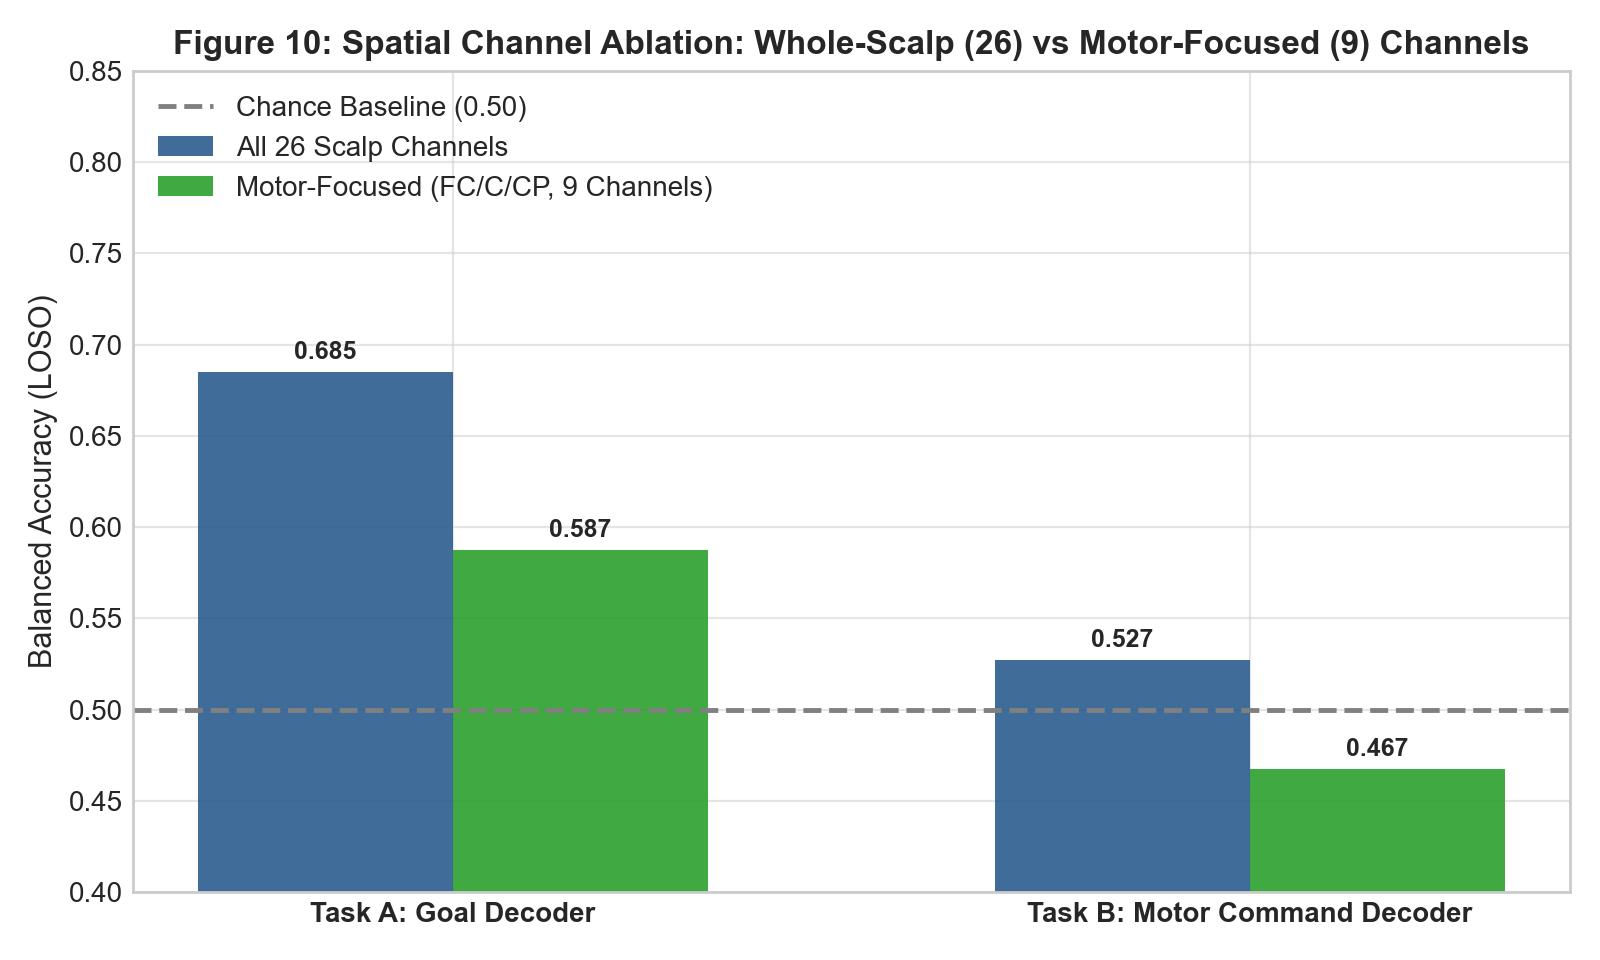

  figure_1_experimental_design.png


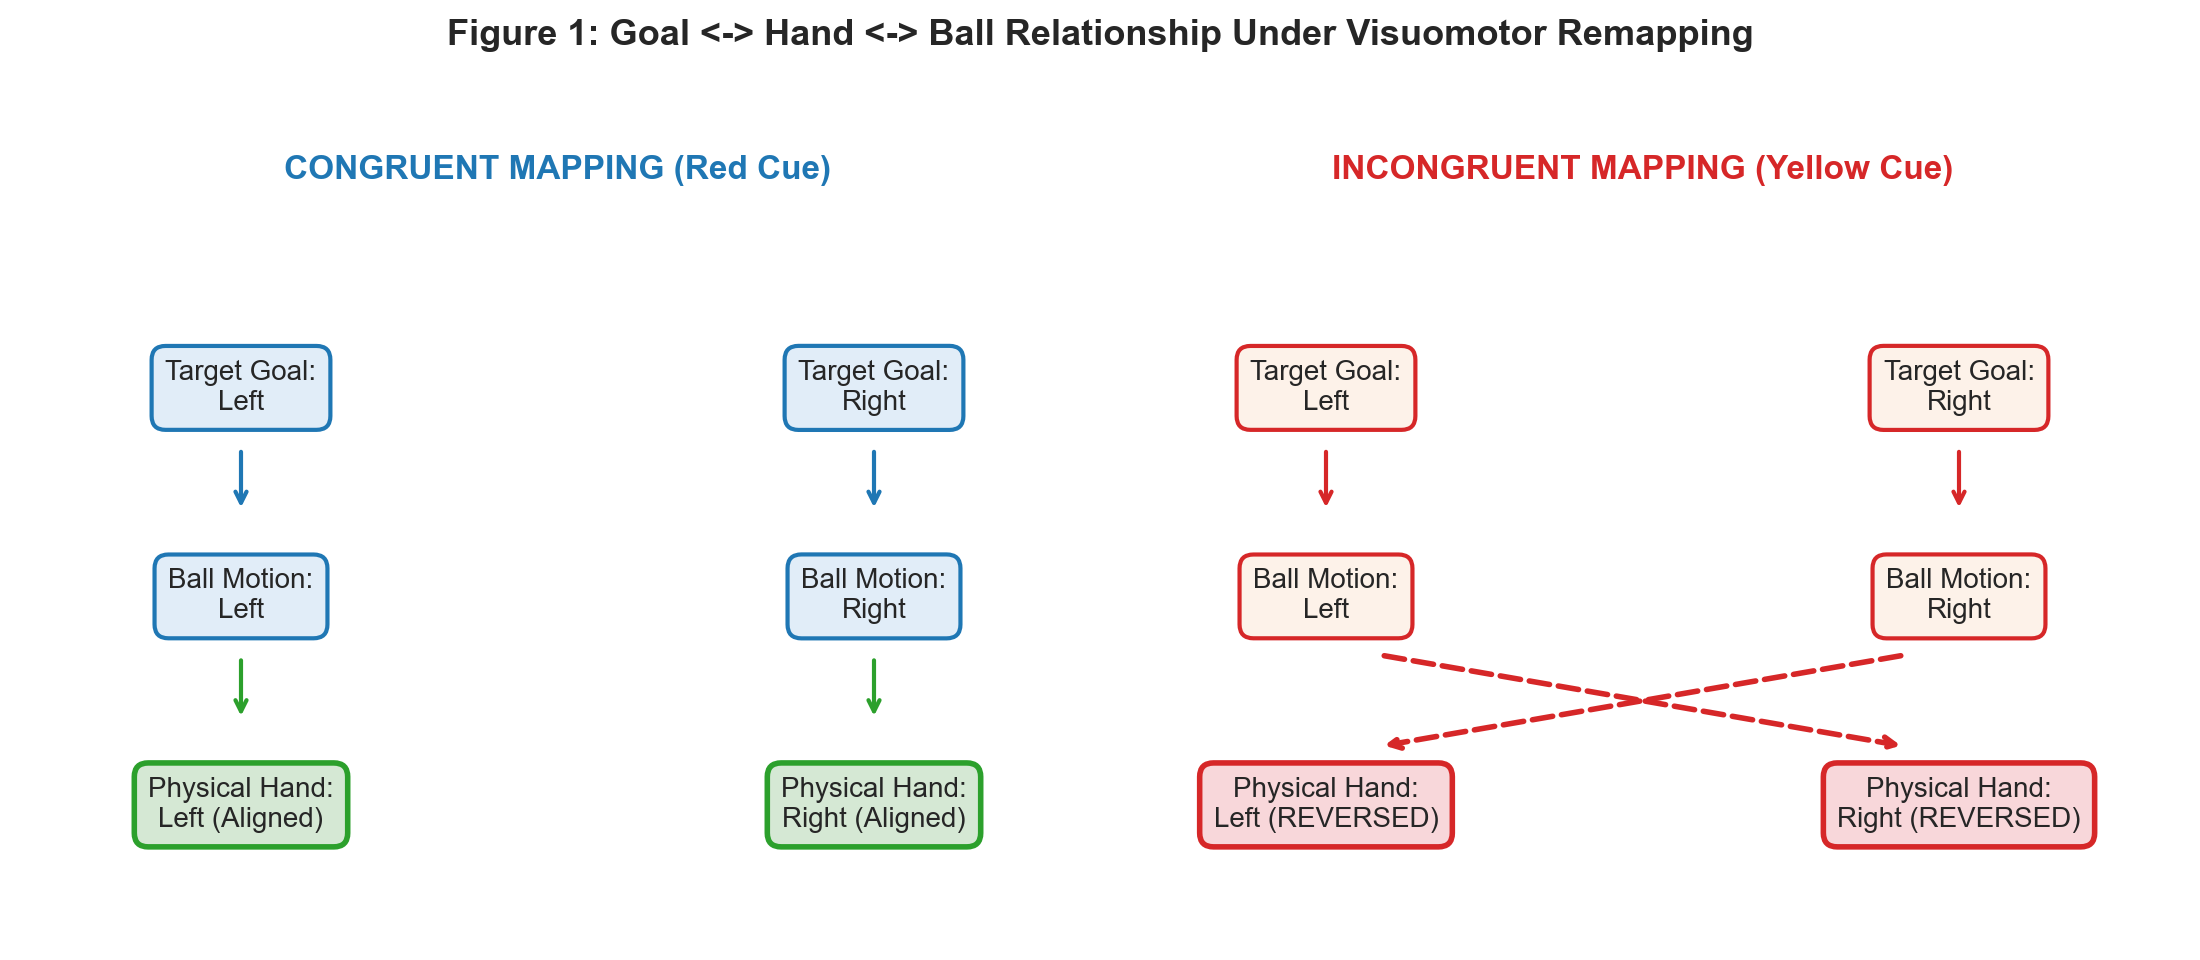

  figure_2_readiness_potential.png


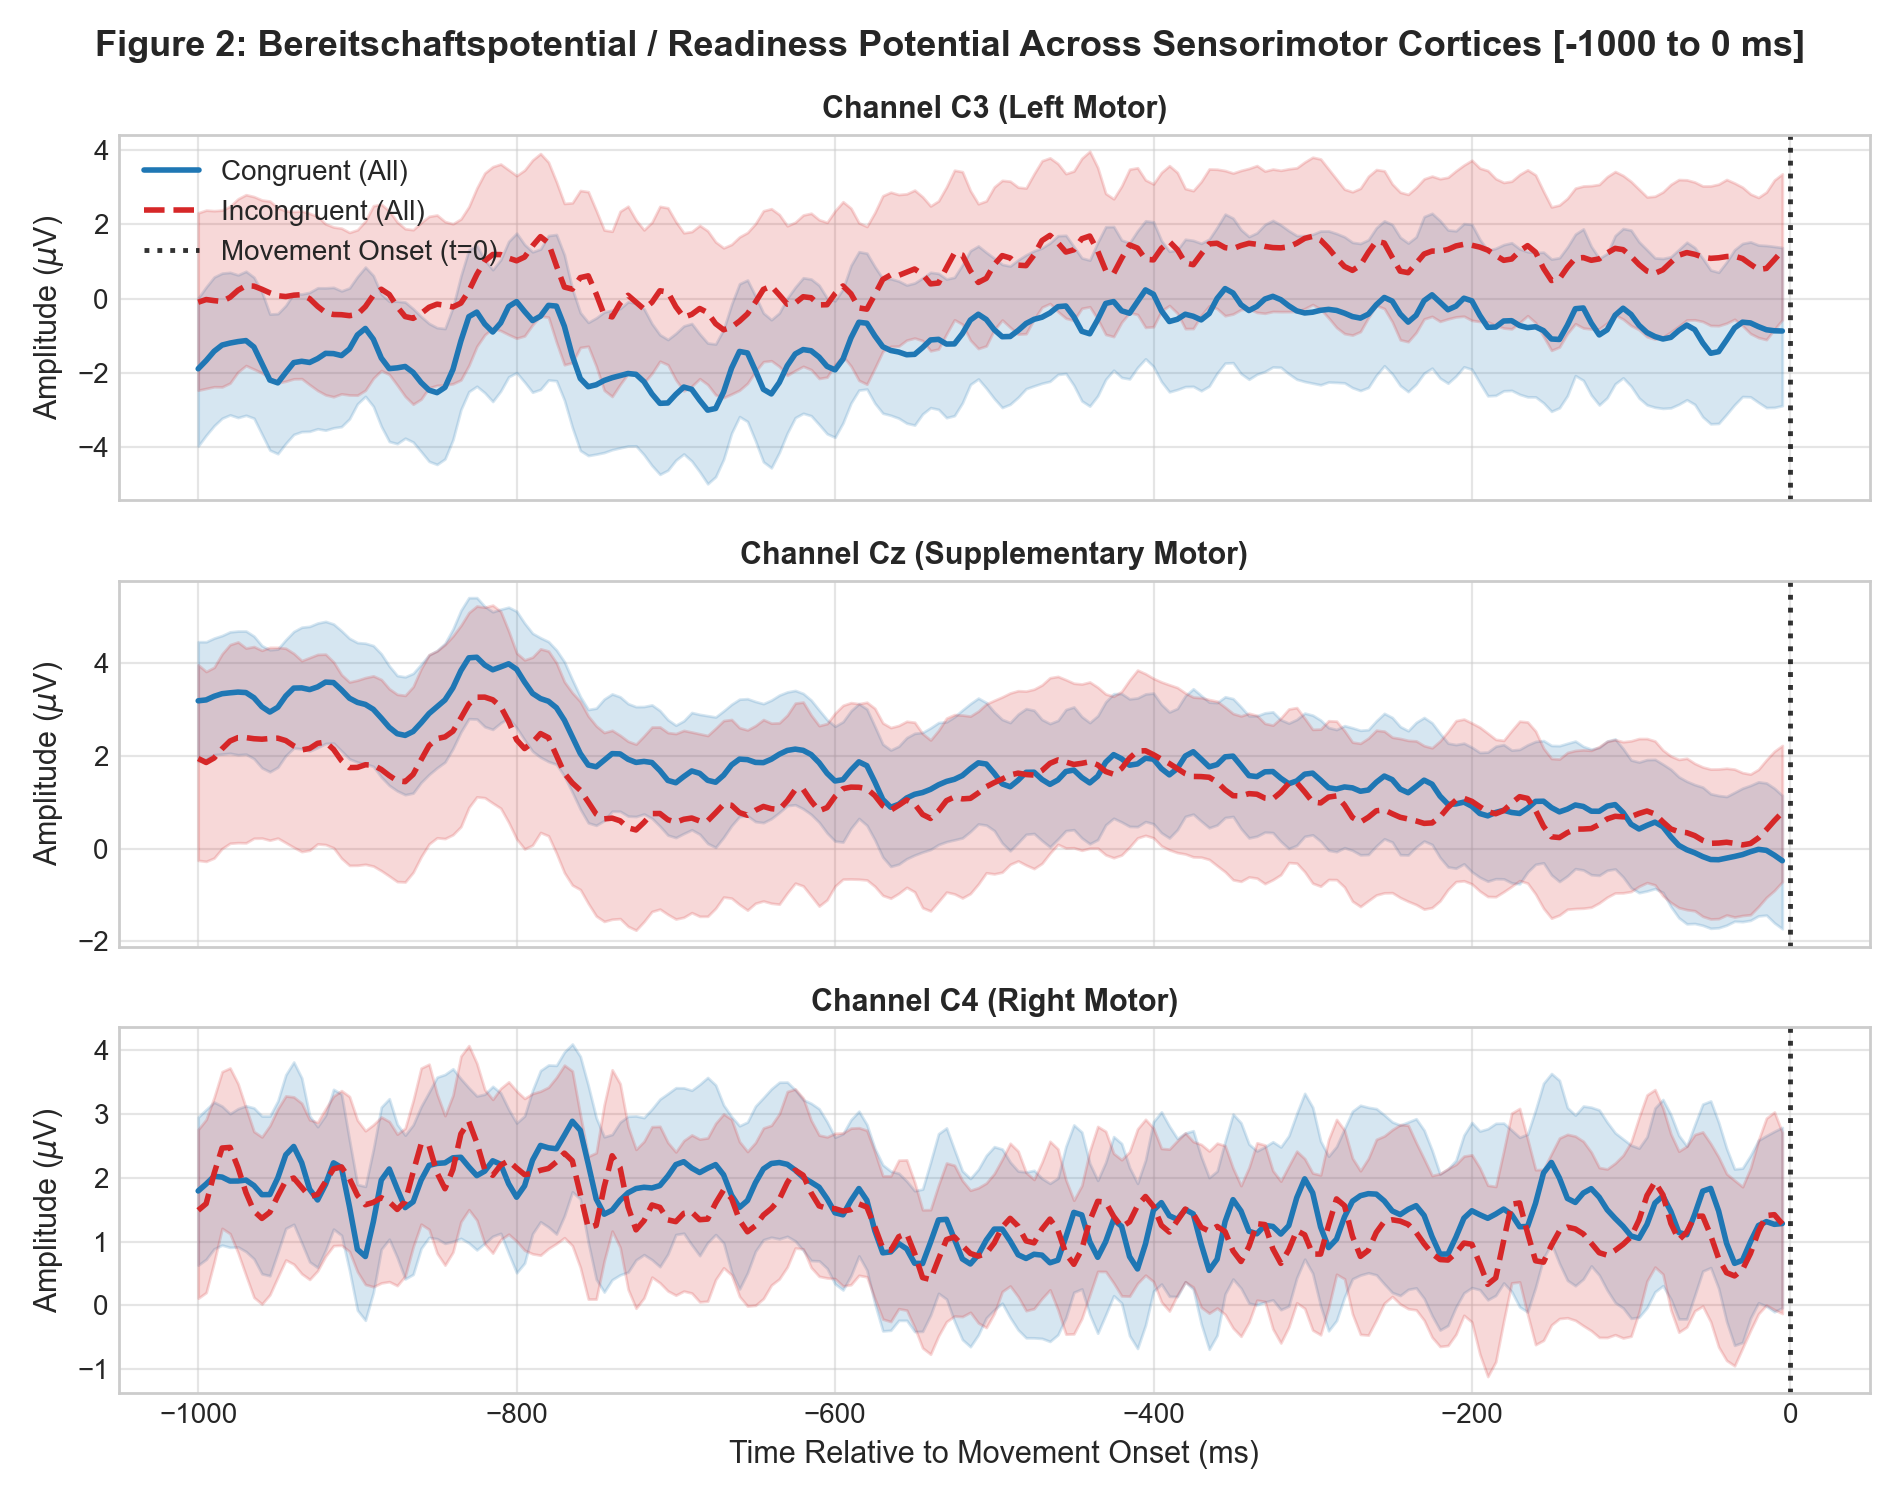

  figure_3_smr_erd.png


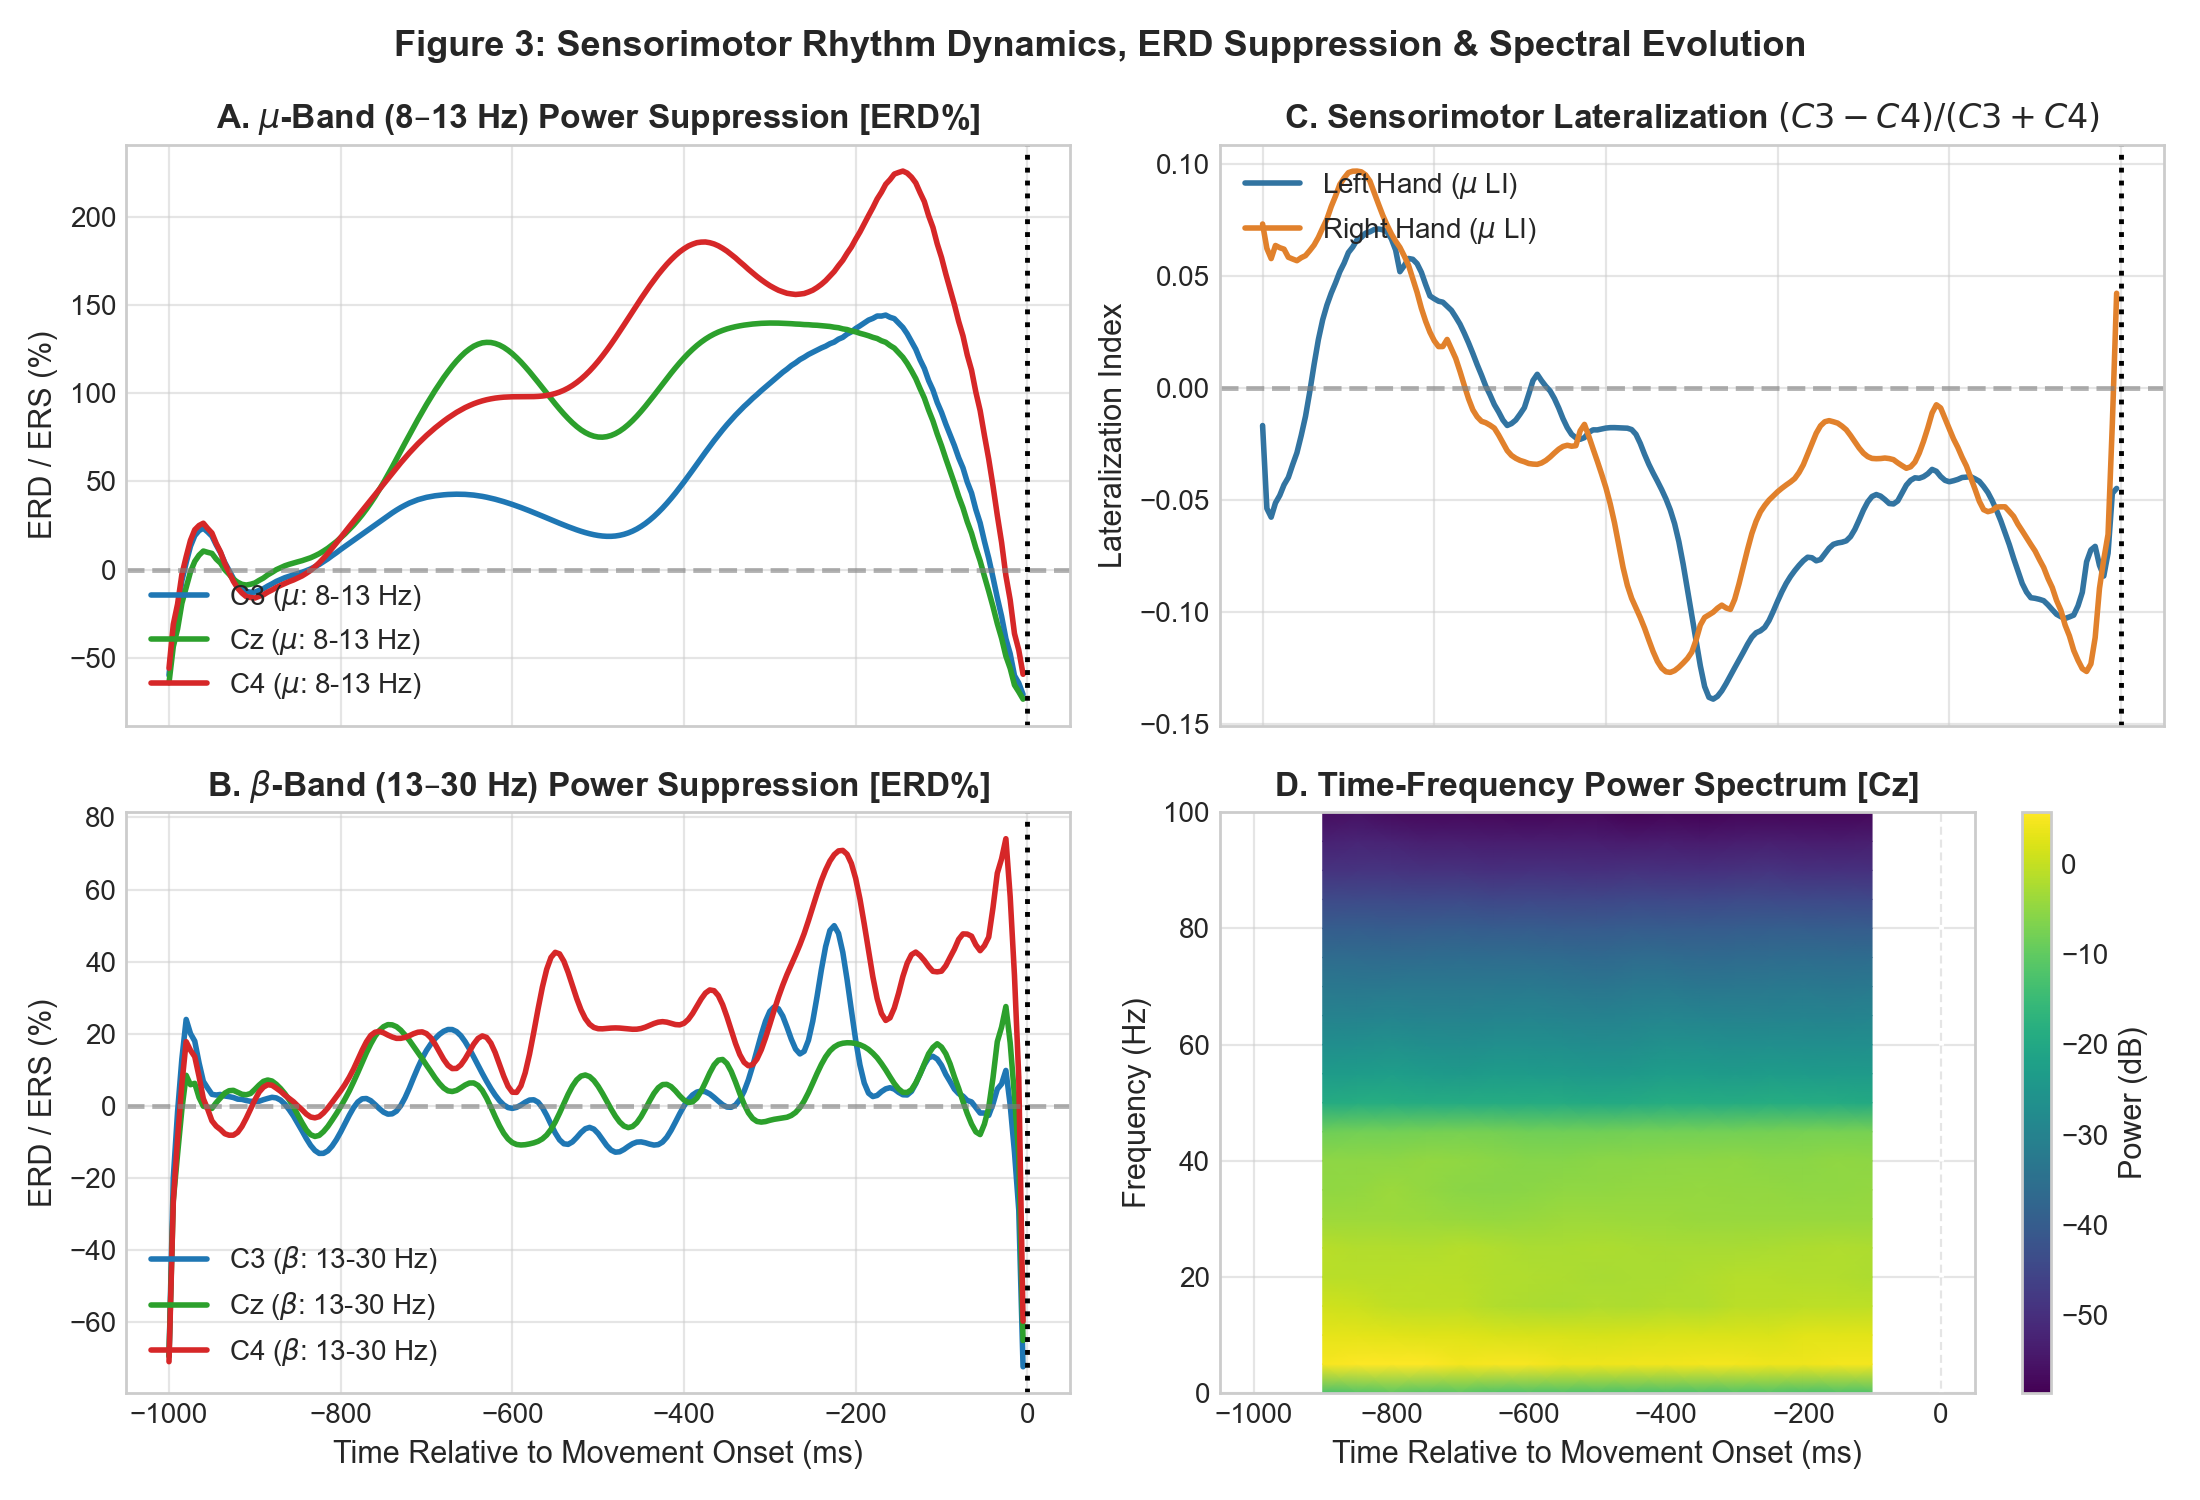

  figure_4_goal_temporal.png


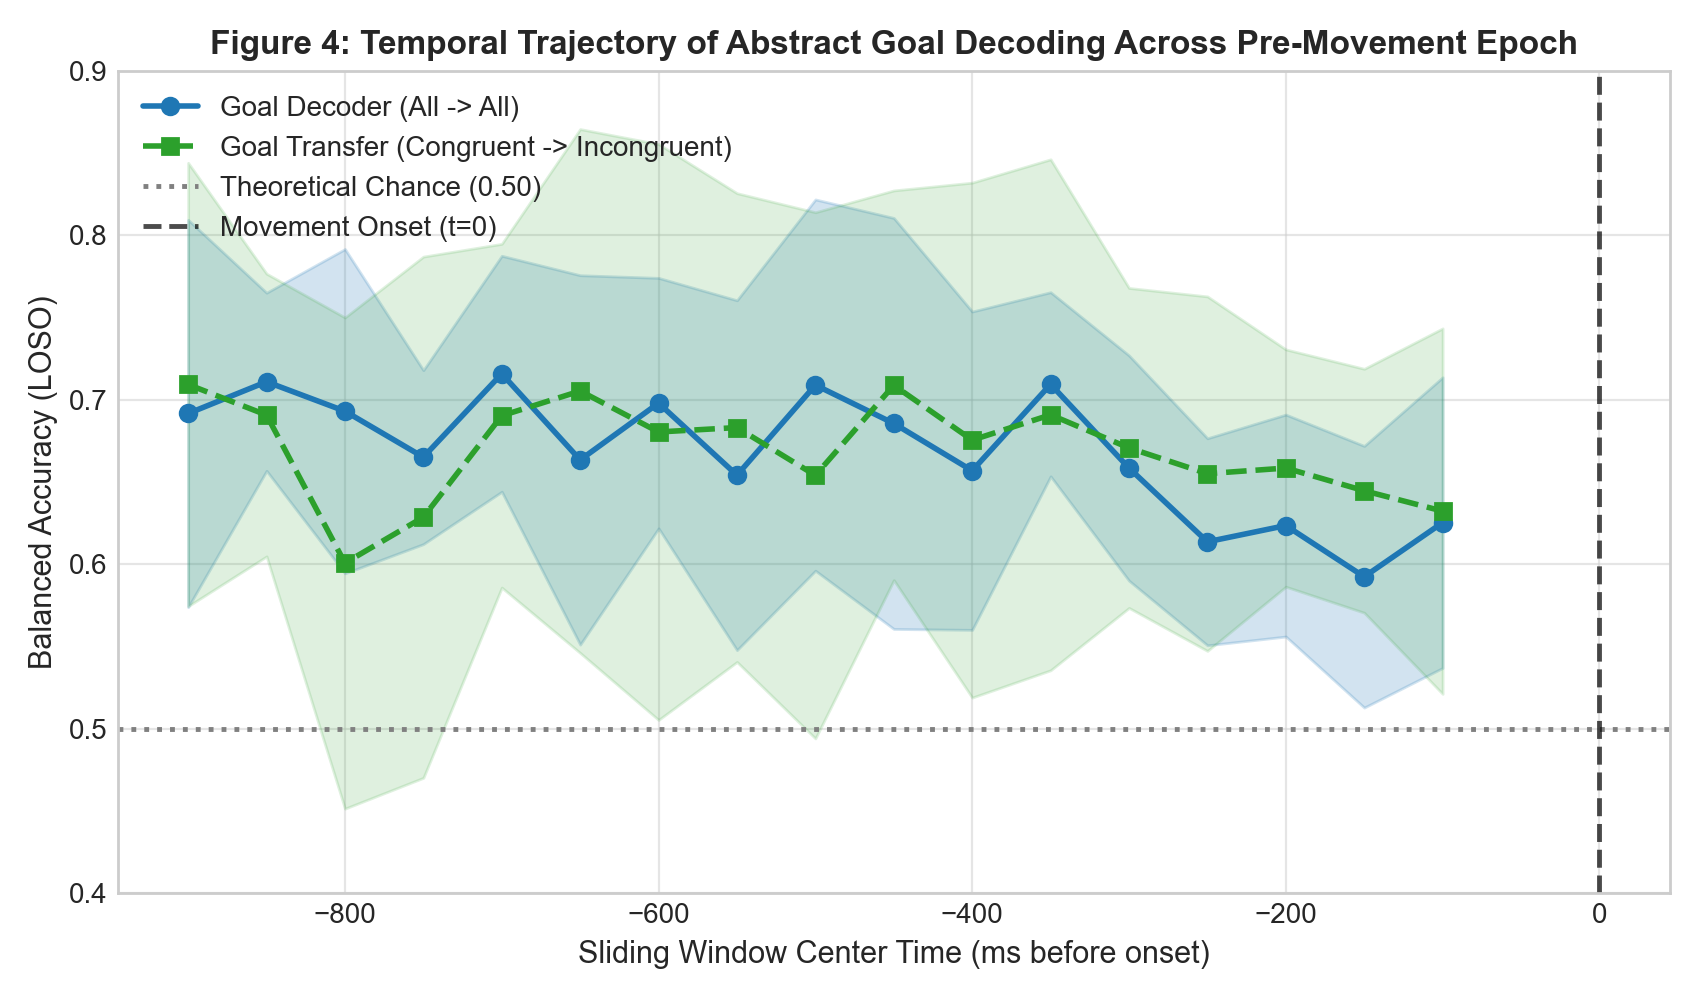

  figure_5_motor_temporal.png


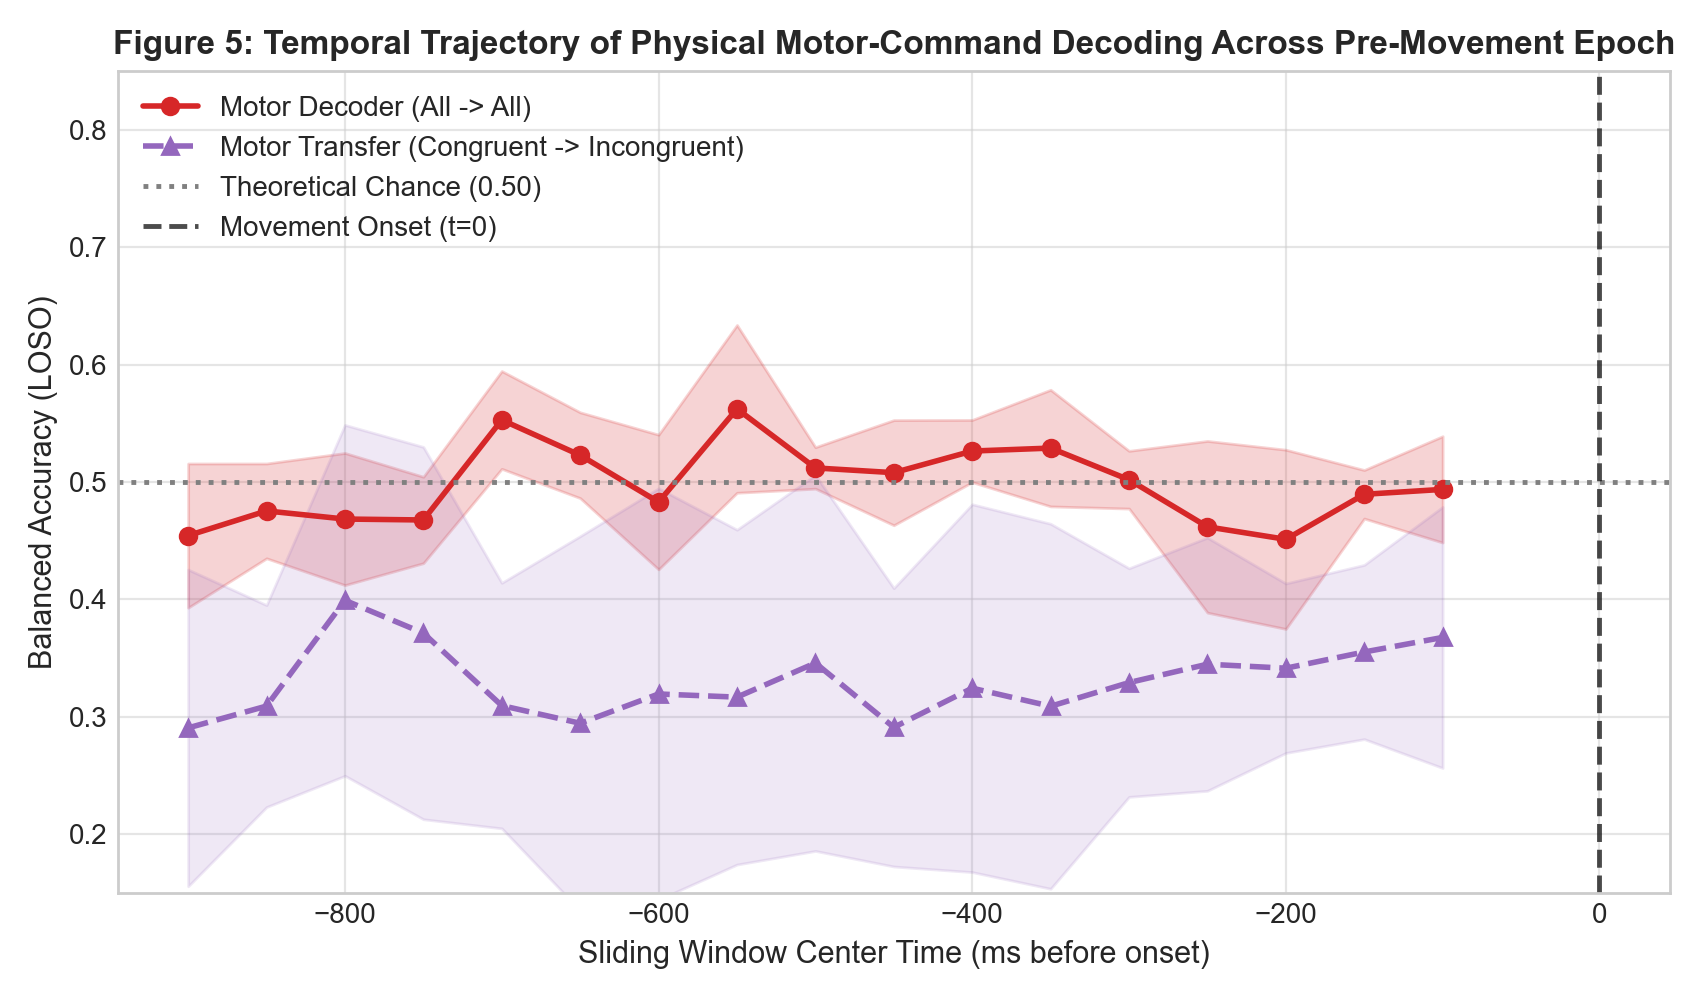

  figure_6_goal_vs_motor_comparison.png


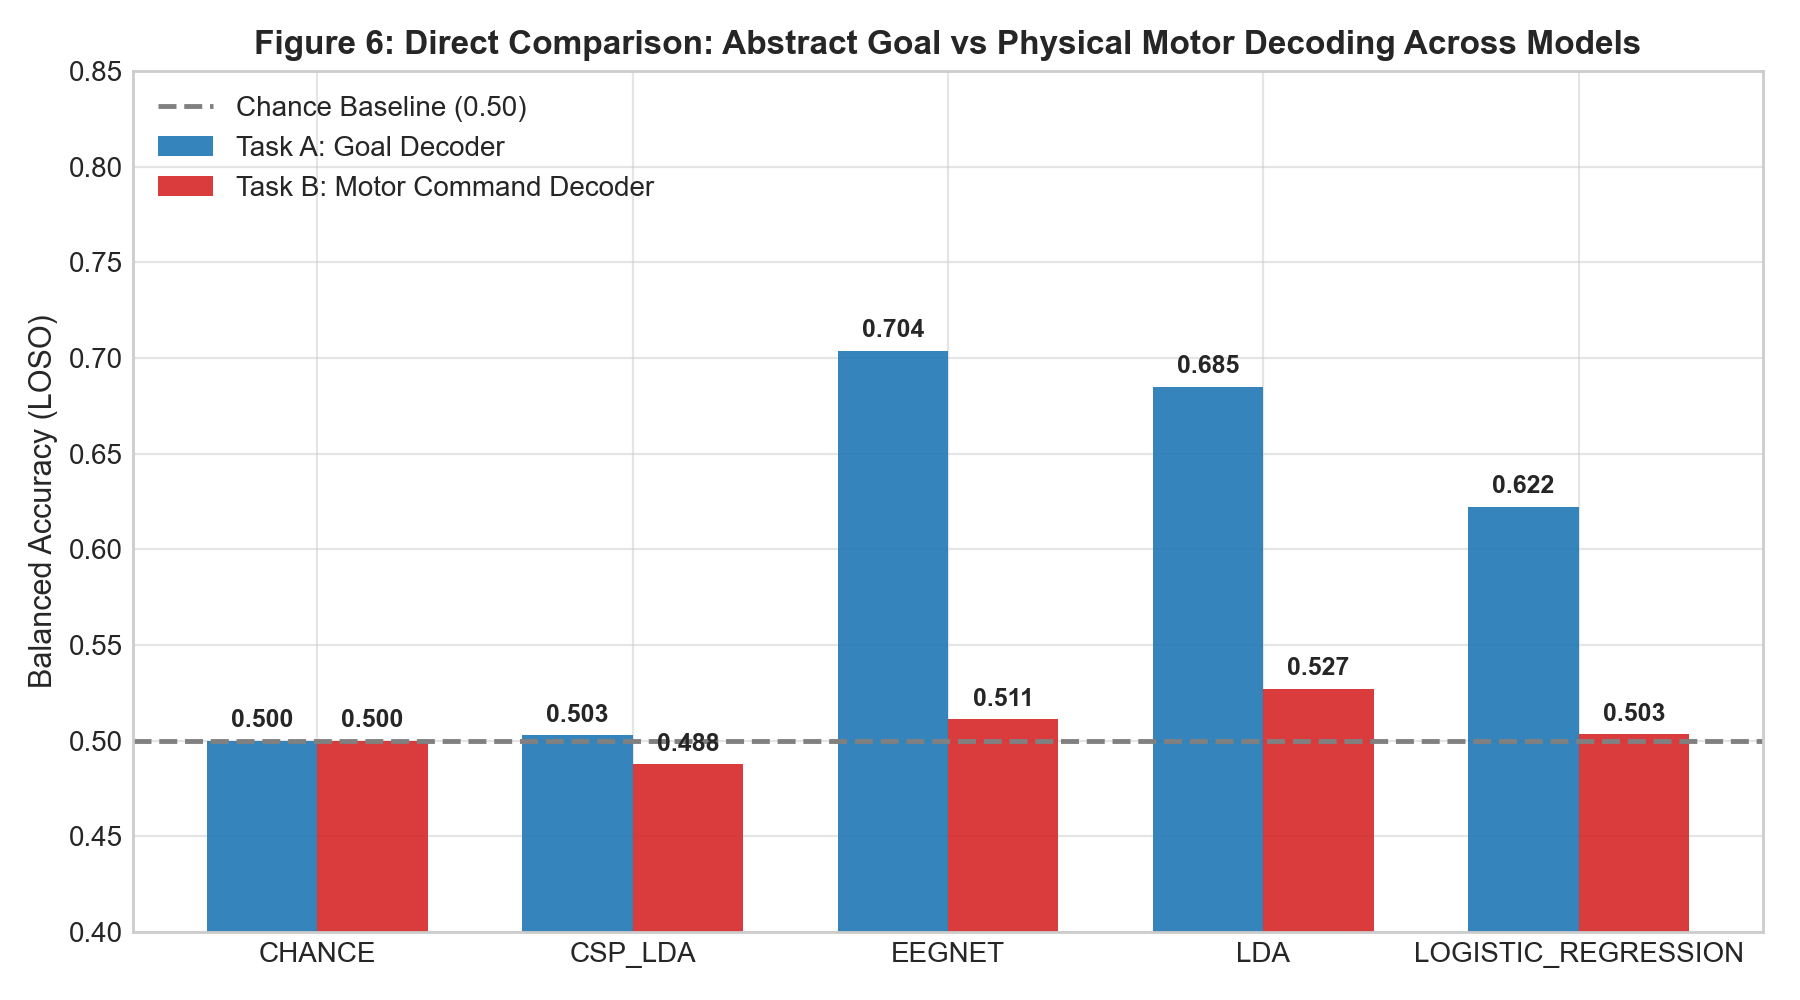

  figure_7_transfer_experiment.png


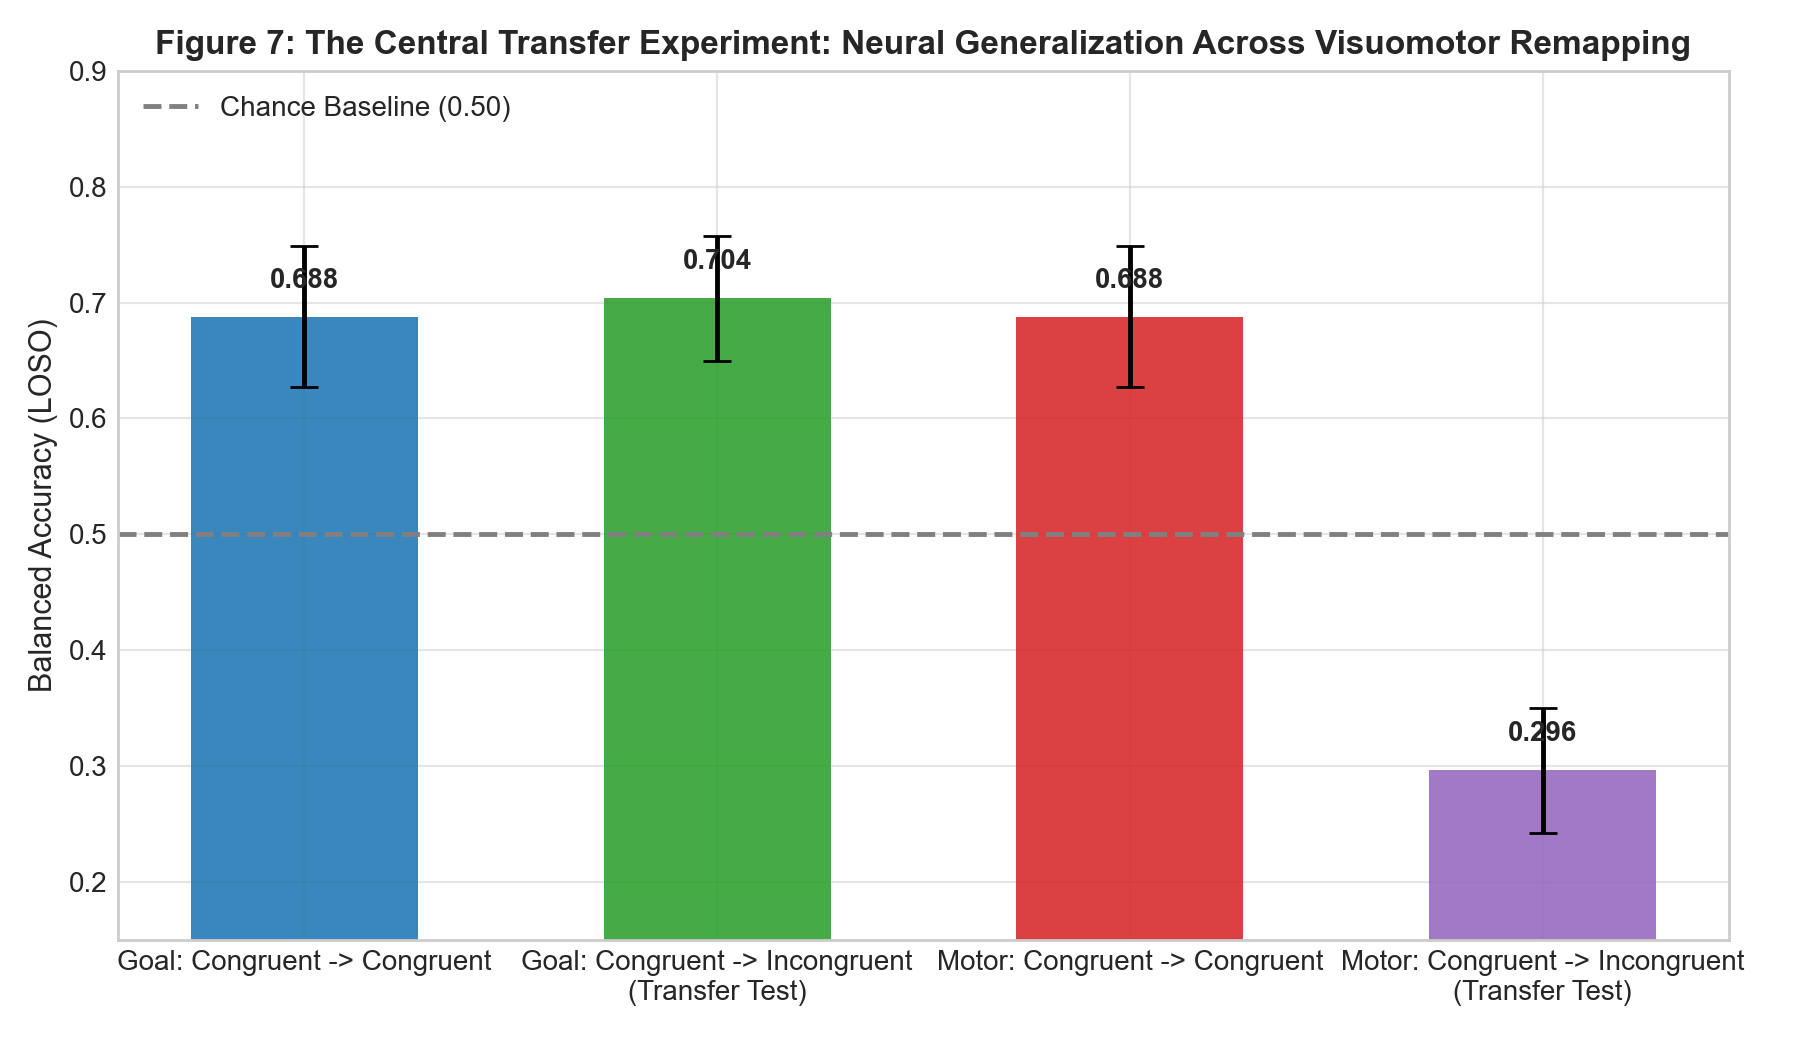

  figure_8_subject_distribution.png


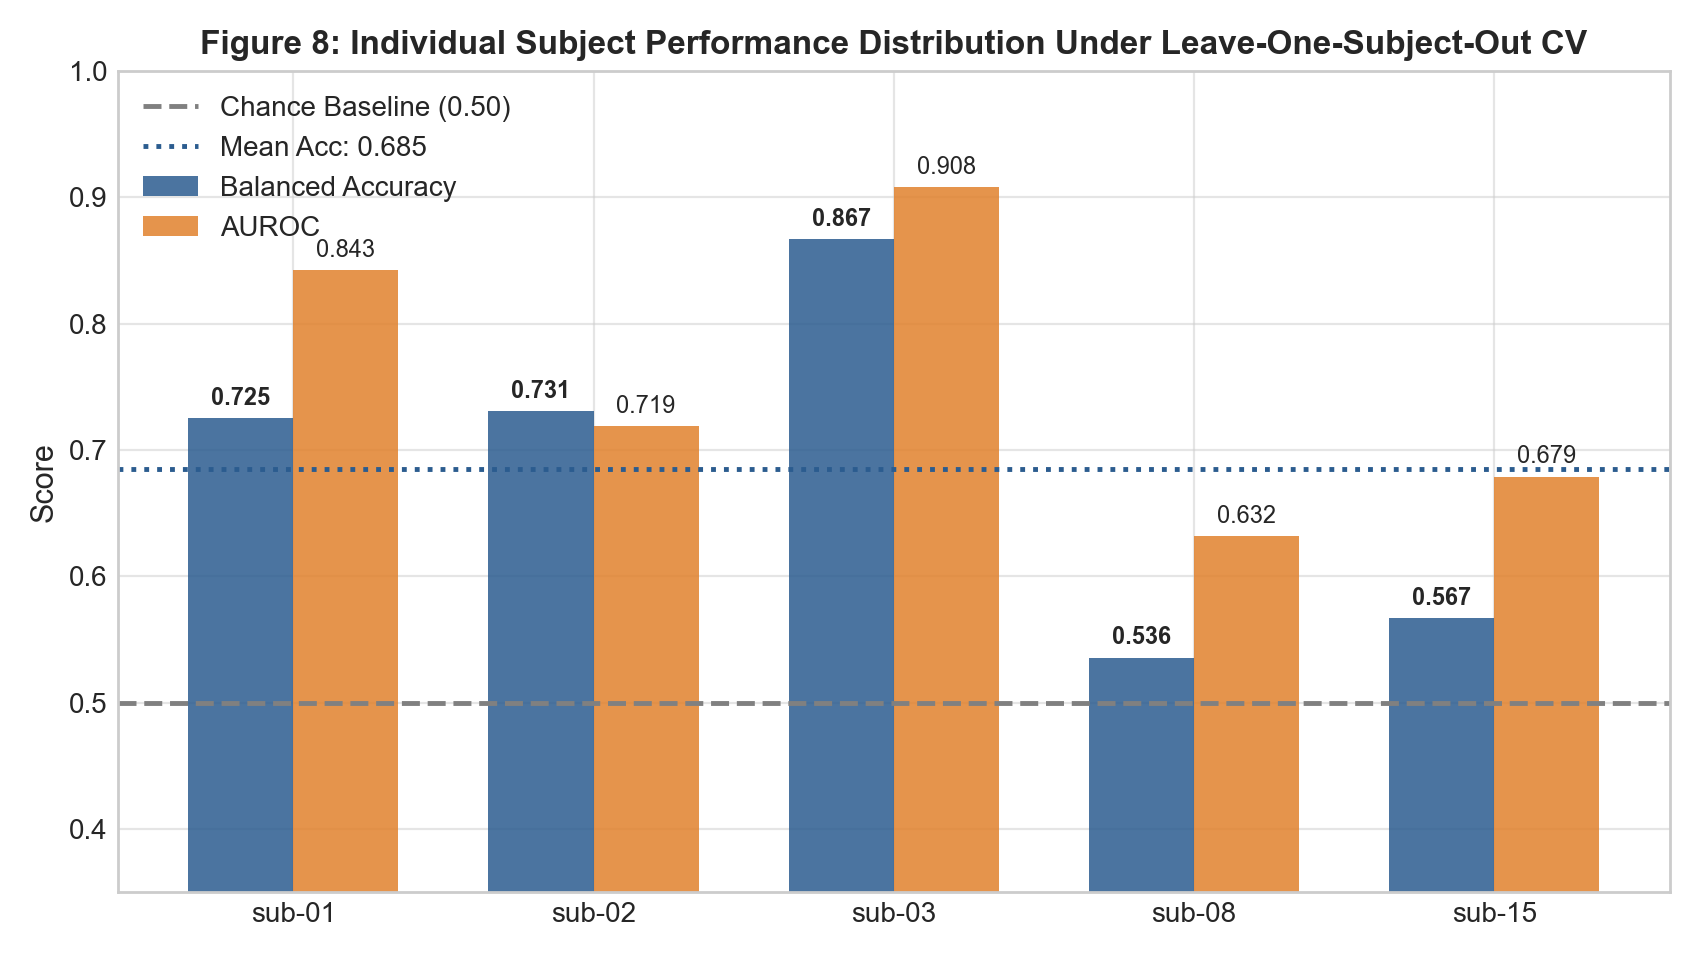

  figure_9_neural_commitment_points.png


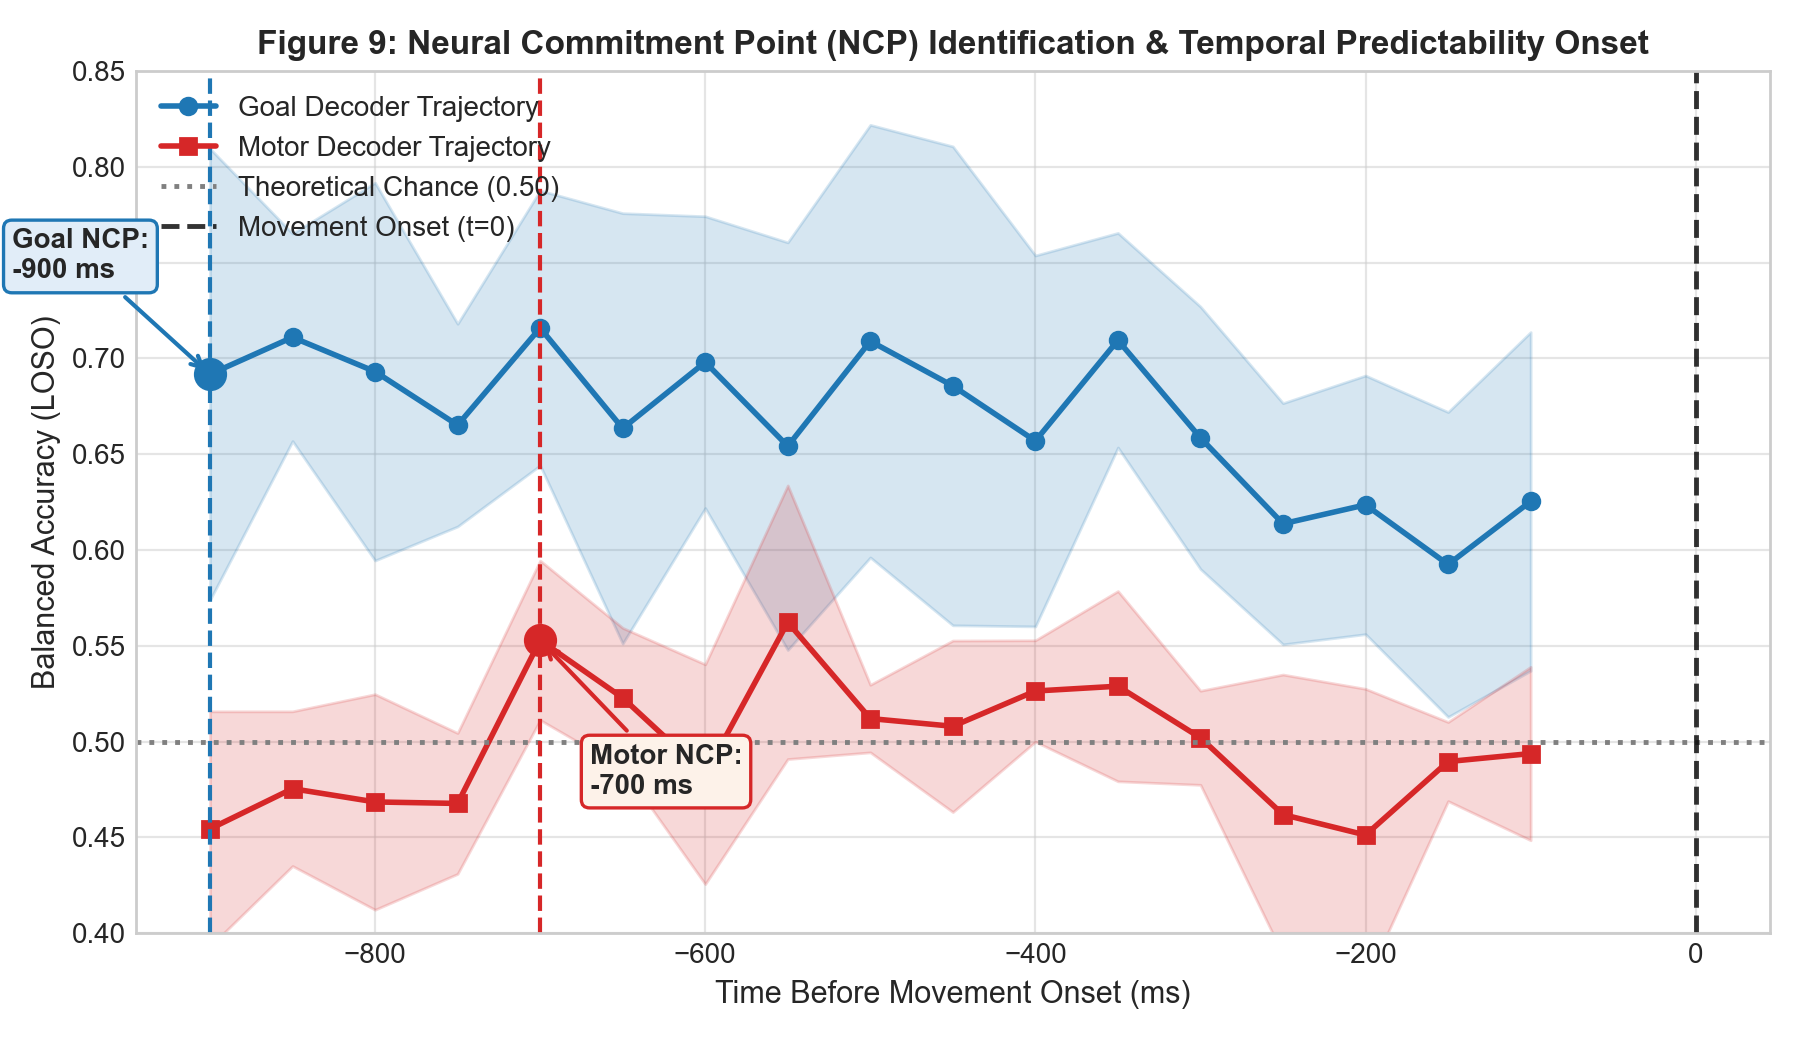

In [10]:
from IPython.display import Image, display

figures = sorted(list(Path("reports/phase_2/figures").glob("figure_*.png")))
print(f"Found {len(figures)} figures:")
for fig_path in figures:
    print(f"  {fig_path.name}")
    display(Image(filename=str(fig_path), width=700))